# 06 · Interprétation du modèle

Les notebooks 01 à 05 cherchent le meilleur score. Celui-ci regarde ce que le modèle a appris :

1. **Quelles variables** pèsent dans la prédiction, et dans quel sens ?
2. **Calibration** : une probabilité de 0.9 correspond-elle à 90 % d'acceptations ?
3. **Par groupe** (origine, ethnicité, sexe, âge) : le modèle est-il aussi juste pour chacun ?
4. **Sans les variables protégées** : que devient le score, et que deviennent les écarts entre groupes ?

Un seul modèle est étudié, « profondeur 6, jeu réduit » (68 colonnes), l'un des trois réglages de l'ensemble final. Les résultats sont dans `artifacts/06_interpretation/`.

In [1]:
# Environnement, chemins et fonctions partagés par les cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def find_project_dir():
    candidates = []
    if os.environ.get('HMDA_PROJECT_DIR'):
        candidates.append(Path(os.environ['HMDA_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir HMDA_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                                        # CSV sources (lecture seule)
ARTIFACTS = PROJECT_DIR / 'artifacts'                                  # Résultats dans un sous-dossier par notebook
PREPARED_DIR = ARTIFACTS / '01_data_exploration'                       # 01 : données préparées et schéma fixe
FEATURE_DIR = ARTIFACTS / '02_feature_engineering' / 'feature_store'   # 02 : feature store
SEED = 42
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


def ensure_catboost():
    """Installe et importe la version fixée de CatBoost pour le réentraînement."""
    global catboost
    try:
        installed = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà chargée ; redémarrer puis relancer le notebook')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'catboost=={CATBOOST_VERSION}'])
        importlib.invalidate_caches()
    import catboost as catboost_module
    if catboost_module.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version chargée : {catboost_module.__version__}')
    catboost = catboost_module
    return catboost_module


def ensure_gpu():
    """Vérifie la présence du GPU NVIDIA avant le réentraînement."""
    global GPU_NAME
    if shutil.which('nvidia-smi') is None:
        raise RuntimeError('GPU requis : choisir un GPU T4 dans le type de session Colab, puis relancer')
    probe = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           text=True, capture_output=True, check=False)
    if probe.returncode != 0 or not probe.stdout.strip():
        raise RuntimeError('GPU NVIDIA indisponible : choisir un T4 puis relancer')
    GPU_NAME = probe.stdout.strip().splitlines()[0]
    return GPU_NAME


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')

Projet : demandes-de-pret-immobilier-aux-etats-unis
Python 3.13.2 | pandas 2.2.3 | numpy 2.1.3


In [2]:
"""Identifiants de stockage historiques et libellés descriptifs.

Les valeurs assurent la reprise exacte des artefacts existants. Les paramètres,
les features et leur ordre sont définis dans les cellules métier.
Cette cellule est intégrée à chaque notebook : aucun import local requis.
"""

MODEL_DEPTH6_INITIAL = 'M0_C11_all'
MODEL_DEPTH6_ENRICHED = 'M1_C11_G7'
MODEL_DEPTH8_ENRICHED = 'M2_C7_G7'
MODEL_DEPTH6_REDUCED = 'M3_C11_lean'
FEATURE_SET_INITIAL = 'ROUND1_ALL'
FEATURE_SET_ENRICHED = 'G7'
FEATURE_SET_REDUCED = 'LEAN'
ENSEMBLE_THREE_MODELS_SEED42 = 'B13_seed42'
ENSEMBLE_MULTISEED = 'B_seeds'
ENSEMBLE_MULTISEED_PREFIX = 'B_seeds_'
ENSEMBLE_FULL_MULTISEED = 'full_Bseeds'
MODEL_INITIAL_POOL_LABEL = 'M0'
LEARNING_CURVE_SUBSET = 'LC_sub80'
LEARNING_CURVE_FULL = 'LC_full'
REDUCED_MODEL_CV_AUC = 'M3_in_13'
BASELINE_CATBOOST_DEPTH6 = 'CatBoost_R1'
BASELINE_CATBOOST_DEPTH8 = 'CatBoost_R2'
LIGHTGBM_LEAVES31 = 'L1_lgbm_leaves31'
LIGHTGBM_LEAVES127 = 'L2_lgbm_leaves127'
OBSERVED_LABELS_ONLY = 'A_base'
SOFT_PSEUDO_LABELS = 'A_pseudo'
LEARNING_CURVE_RUN_PATTERN = 'LC_*__fold?.json'
LEARNING_CURVE_FULL_PATTERN = 'LC_full__fold?.json'
REDUCED_MODEL_RUN_PATTERN = 'M3_C11_lean__fold?.json'
LIGHTGBM_RUN_PATTERN = 'L*_lgbm_*__fold?.json'
PSEUDO_LABEL_RUN_PATTERN = 'A_*__fold?.json'
FULL_ENSEMBLE_SUBMISSION = 'submission_full_Bseeds.csv'
ABLATION_ORIGINAL = 'F0_base'
ABLATION_ADD_DTI = 'F1_dti'
ABLATION_ADD_LTV = 'F2_ltv'
ABLATION_ADD_INCOME = 'F3_income'
ABLATION_ADD_MISSINGNESS = 'F4_missing'
ABLATION_ADD_GEOGRAPHIC_COUNTS = 'F5_freq'
ABLATION_INITIAL = 'F6_all'
ABLATION_INITIAL_REFERENCE = 'G0_all'
ABLATION_ADD_LTV_PRECISION = 'G1_precision'
ABLATION_ADD_LTV_THRESHOLDS = 'G2_thresholds'
ABLATION_ADD_IMPLIED_VALUE = 'G3_implied'
ABLATION_ADD_TERM = 'G4_term'
ABLATION_ENRICHED_WITH_COUNTS = 'G5_round2_all'
ABLATION_CORE_WITHOUT_COUNTS = 'G6_nofreq'
ABLATION_ENRICHED = 'G7_nofreq_round2_all'
ABLATION_ENRICHED_REFERENCE = 'H0_G7'
ABLATION_ADD_PRODUCT_FLAGS = 'H1_purpose'
ABLATION_ADD_LTV_CONSISTENCY = 'H2_ltv_consistency'
ABLATION_ADD_RISK_INTERACTIONS = 'H3_risk_layers'
ABLATION_ADD_TRACT_INCOME = 'H4_tract_income'
ABLATION_ALL_PRODUCT_RISK = 'H5_round3_all'
TUNING_DEPTH8_FIXED1600 = 'B0_R2_fixed1600'
TUNING_DEPTH8_LR005_L2_3 = 'C1_d8_lr05_l2_3_es'
TUNING_DEPTH6_LR003_L2_10 = 'C6_d6_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_10 = 'C3_d8_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_3 = 'C2_d8_lr03_l2_3'
TUNING_DEPTH8_LR003_L2_30 = 'C4_d8_lr03_l2_30'
TUNING_DEPTH8_BERNOULLI80 = 'C7_d8_lr03_l2_10_sub80'
TUNING_DEPTH8_WITH_DTI = 'C8_d8_lr03_l2_10_DTI'
TUNING_DEPTH10_LR003_L2_10 = 'C5_d10_lr03_l2_10'
TUNING_DEPTH8_LR002_L2_10 = 'C9_d8_lr02_l2_10'
TUNING_DEPTH8_L2_30_BERNOULLI80 = 'C10_d8_lr03_l2_30_sub80'
TUNING_DEPTH6_BERNOULLI80 = 'C11_d6_lr03_l2_10_sub80'
TRAINING_STANDARD = 'V0_base'
TRAINING_ORDERED = 'V1_ordered'
TRAINING_NEWTON_SCORE = 'V2_newtonL2'
TRAINING_DEPTHWISE = 'V3_depthwise'
TRAINING_LOSSGUIDE = 'V4_lossguide'
TRAINING_POISSON = 'V5_poisson'
TRAINING_ROWS066 = 'V6_sub066'
TRAINING_BINS254 = 'V7_border254'
TRAINING_NO_CATEGORY_COMBINATIONS = 'V8_ctr1'
TRAINING_DROP_REDUNDANT_DEMOGRAPHICS = 'V9_drop_demo'
MEAN_GAIN_VS_SOURCE_FEATURES = 'mean_delta_vs_F0'
FOLDS_BETTER_THAN_SOURCE_FEATURES = 'folds_better_than_F0'
MEAN_GAIN_VS_INITIAL_FEATURES = 'mean_delta_vs_G0'
FOLDS_BETTER_THAN_INITIAL_FEATURES = 'folds_better_than_G0'
MEAN_GAIN_VS_ENRICHED_FEATURES = 'mean_delta_vs_H0'
FOLDS_BETTER_THAN_ENRICHED_FEATURES = 'folds_better_than_H0'
MEAN_GAIN_VS_FIXED_ITERATIONS = 'mean_delta_vs_B0'
FOLDS_BETTER_THAN_FIXED_ITERATIONS = 'folds_better_than_B0'
MEAN_GAIN_VS_STANDARD_BOOSTING = 'mean_delta_vs_V0'
FOLDS_BETTER_THAN_STANDARD_BOOSTING = 'folds_better_than_V0'
GAIN_VS_THREE_MODEL_ENSEMBLE = 'delta_vs_B13'
FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE = 'folds_better_than_B13'
TABM_ENSEMBLE_SUBMISSION_PREFIX = 'submission_Bseeds_TabM_w'
PURPOSE_ABLATION = 'feature block ablation, fast GPU CatBoost, paired vs F0_base'
PURPOSE_TRAINING_MODES = 'data-efficiency screen on M3 features; inner 15% early stop, score probe model on outer fold'
PURPOSE_TABM = 'TabM-mini (PyTorch) on G7 features; inner 15% early stop, no outer refit'
PURPOSE_FULL_REFIT = 'learning curve (80% vs 100% of outer-train) + full-data refit of M1-M3 x 3 seeds'

DISPLAY_LABELS = {
    MODEL_DEPTH6_INITIAL: 'CatBoost profondeur 6 · variables initiales',
    MODEL_DEPTH6_ENRICHED: 'CatBoost profondeur 6 · variables enrichies',
    MODEL_DEPTH8_ENRICHED: 'CatBoost profondeur 8 · variables enrichies',
    MODEL_DEPTH6_REDUCED: 'CatBoost profondeur 6 · variables réduites',
    FEATURE_SET_INITIAL: 'Variables initiales (68 colonnes)',
    FEATURE_SET_ENRICHED: 'Variables enrichies (72 colonnes)',
    FEATURE_SET_REDUCED: 'Variables réduites (68 colonnes)',
    ENSEMBLE_THREE_MODELS_SEED42: 'Ensemble de trois modèles · graine 42',
    ENSEMBLE_MULTISEED: 'Ensemble de trois modèles et trois graines',
    ENSEMBLE_MULTISEED_PREFIX: 'Ensemble multigraines · ',
    ENSEMBLE_FULL_MULTISEED: 'Ensemble multigraines sur toutes les données',
    MODEL_INITIAL_POOL_LABEL: 'CatBoost profondeur 6 · variables initiales',
    LEARNING_CURVE_SUBSET: 'Apprentissage sur 67 200 lignes',
    LEARNING_CURVE_FULL: 'Apprentissage sur 84 000 lignes',
    REDUCED_MODEL_CV_AUC: 'AUC du modèle réduit en validation croisée',
    BASELINE_CATBOOST_DEPTH6: 'CatBoost profondeur 6',
    BASELINE_CATBOOST_DEPTH8: 'CatBoost profondeur 8',
    LIGHTGBM_LEAVES31: 'LightGBM · 31 feuilles',
    LIGHTGBM_LEAVES127: 'LightGBM · 127 feuilles',
    OBSERVED_LABELS_ONLY: 'Cibles observées uniquement',
    SOFT_PSEUDO_LABELS: 'Pseudo-étiquettes souples',
    LEARNING_CURVE_RUN_PATTERN: 'Courbe d’apprentissage',
    LEARNING_CURVE_FULL_PATTERN: 'Courbe sur 84 000 lignes',
    REDUCED_MODEL_RUN_PATTERN: 'Validation croisée du modèle réduit',
    LIGHTGBM_RUN_PATTERN: 'Modèles LightGBM',
    PSEUDO_LABEL_RUN_PATTERN: 'Comparaison des pseudo-étiquettes',
    FULL_ENSEMBLE_SUBMISSION: 'Soumission de l’ensemble complet',
    ABLATION_ORIGINAL: 'Variables sources',
    ABLATION_ADD_DTI: 'Ajout des bornes DTI',
    ABLATION_ADD_LTV: 'Ajout de la cohérence LTV',
    ABLATION_ADD_INCOME: 'Ajout des ratios de revenu',
    ABLATION_ADD_MISSINGNESS: 'Ajout des valeurs manquantes',
    ABLATION_ADD_GEOGRAPHIC_COUNTS: 'Ajout des fréquences géographiques',
    ABLATION_INITIAL: 'Toutes les variables initiales',
    ABLATION_INITIAL_REFERENCE: 'Référence : variables initiales',
    ABLATION_ADD_LTV_PRECISION: 'Ajout de la précision LTV',
    ABLATION_ADD_LTV_THRESHOLDS: 'Ajout des seuils LTV',
    ABLATION_ADD_IMPLIED_VALUE: 'Ajout de la valeur immobilière implicite',
    ABLATION_ADD_TERM: 'Ajout des variables de durée',
    ABLATION_ENRICHED_WITH_COUNTS: 'Variables enrichies avec fréquences géographiques',
    ABLATION_CORE_WITHOUT_COUNTS: 'Variables initiales sans fréquences géographiques',
    ABLATION_ENRICHED: 'Variables enrichies sans fréquences géographiques',
    ABLATION_ENRICHED_REFERENCE: 'Référence : variables enrichies',
    ABLATION_ADD_PRODUCT_FLAGS: 'Ajout des indicateurs de produit',
    ABLATION_ADD_LTV_CONSISTENCY: 'Ajout de la cohérence des intervalles LTV',
    ABLATION_ADD_RISK_INTERACTIONS: 'Ajout des interactions de risque',
    ABLATION_ADD_TRACT_INCOME: 'Ajout du revenu relatif au secteur',
    ABLATION_ALL_PRODUCT_RISK: 'Ajout de tous les blocs produit et risque',
    TUNING_DEPTH8_FIXED1600: 'Profondeur 8 · 1 600 itérations fixes',
    TUNING_DEPTH8_LR005_L2_3: 'Profondeur 8 · taux 0.05 · L2=3',
    TUNING_DEPTH6_LR003_L2_10: 'Profondeur 6 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_10: 'Profondeur 8 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_3: 'Profondeur 8 · taux 0.03 · L2=3',
    TUNING_DEPTH8_LR003_L2_30: 'Profondeur 8 · taux 0.03 · L2=30',
    TUNING_DEPTH8_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TUNING_DEPTH8_WITH_DTI: 'Profondeur 8 · taux 0.03 · L2=10 · bornes DTI',
    TUNING_DEPTH10_LR003_L2_10: 'Profondeur 10 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR002_L2_10: 'Profondeur 8 · taux 0.02 · L2=10',
    TUNING_DEPTH8_L2_30_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8',
    TUNING_DEPTH6_BERNOULLI80: 'Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TRAINING_STANDARD: 'Boosting standard',
    TRAINING_ORDERED: 'Boosting ordonné',
    TRAINING_NEWTON_SCORE: 'Score NewtonL2',
    TRAINING_DEPTHWISE: 'Croissance par profondeur',
    TRAINING_LOSSGUIDE: 'Croissance guidée par la perte',
    TRAINING_POISSON: 'Échantillonnage Poisson',
    TRAINING_ROWS066: 'Échantillonnage des lignes à 0.66',
    TRAINING_BINS254: '254 seuils numériques',
    TRAINING_NO_CATEGORY_COMBINATIONS: 'Sans combinaison de catégories',
    TRAINING_DROP_REDUNDANT_DEMOGRAPHICS: 'Sans colonnes démographiques redondantes',
    MEAN_GAIN_VS_SOURCE_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_SOURCE_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_INITIAL_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_INITIAL_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_ENRICHED_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_ENRICHED_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_FIXED_ITERATIONS: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_FIXED_ITERATIONS: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_STANDARD_BOOSTING: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_STANDARD_BOOSTING: 'Plis meilleurs que la référence',
    GAIN_VS_THREE_MODEL_ENSEMBLE: 'Gain face à l’ensemble de trois modèles',
    FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE: 'Plis meilleurs que l’ensemble de trois modèles',
    TABM_ENSEMBLE_SUBMISSION_PREFIX: 'submission_Bseeds_TabM_w',
}

def semantic_label(value):
    """Décrit un identifiant historique pour l’affichage uniquement."""
    if not isinstance(value, str):
        return value
    # Un chemin affiché doit continuer à désigner le fichier réellement présent.
    if value.endswith(('.csv', '.json', '.parquet', '.npy')):
        return value
    if value in DISPLAY_LABELS:
        return DISPLAY_LABELS[value]
    for stored in sorted(DISPLAY_LABELS, key=len, reverse=True):
        value = value.replace(stored, DISPLAY_LABELS[stored])
    return value


def display_named(value, *args, **kwargs):
    """Affiche une copie : index, colonnes et libellés lisibles, calculs inchangés."""
    if isinstance(value, (pd.DataFrame, pd.Series)):
        value = value.copy(deep=True)
        if not isinstance(value.index, pd.MultiIndex):
            value.index = value.index.map(semantic_label)
        if isinstance(value, pd.DataFrame):
            value.columns = value.columns.map(semantic_label)
            for column in value.select_dtypes(include=['object', 'string']).columns:
                value[column] = value[column].map(semantic_label)
        elif value.dtype == object:
            value = value.map(semantic_label)
    display(value, *args, **kwargs)

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : les notebooks relisent les résultats sauvegardés dans `artifacts/`. Deux exceptions : le notebook 01 entraîne un petit modèle de contrôle sur CPU et le notebook 02 réécrit les variables. Pour refaire une expérience, mettre son bouton à `True` et choisir un **GPU T4** si le bloc le demande. Les modèles déjà entraînés sont sauvegardés et ne sont pas refaits.

In [3]:
TRAIN = {
    'protected_ablation': False,   # référence et modèle sans variables protégées, cinq folds, valeurs de Shapley (GPU, environ 75 min)
}

## 0. Chargement des données et des variables

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


manifest_path = PREPARED_DIR / 'manifest.json'
schema_path = PREPARED_DIR / 'schema.json'
if not manifest_path.is_file() or not schema_path.is_file():
    raise FileNotFoundError(
        f'Fichier manquant : {manifest_path} ou {schema_path} ; exécuter d’abord 01_data_exploration.ipynb'
    )
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
schema = json.loads(schema_path.read_text(encoding='utf-8'))
require(manifest['schema_version'] == schema['schema_version'] == '1.0', 'Version du contrat de données incompatible')
require(manifest['seed'] == SEED and manifest['n_splits'] == 5, 'Configuration des cinq folds incompatible')
require(set(manifest['source_files']) == {'train.csv', 'test.csv', 'sample_submission.csv'},
        'Liste des fichiers source incomplète')
expected_prepared = {
    'train_features.csv', 'test_features.csv', 'train_labels.csv',
    'test_ids.csv', 'folds.csv', 'audit.csv', 'schema.json',
}
require(set(manifest['output_files']) == expected_prepared, 'Liste des fichiers préparés incomplète')
for name, info in manifest['source_files'].items():
    path = DATA_DIR / name
    require(path.is_file(), f'Données source manquantes : {path}')
    require(sha256_file(path) == info['sha256'], f'Fichier source modifié : {name} ; réexécuter 01')
for name, info in manifest['output_files'].items():
    path = PREPARED_DIR / name
    require(path.is_file(), f'Fichier préparé manquant : {path}')
    require(sha256_file(path) == info['sha256'], f'Empreinte du fichier préparé différente : {name} ; réexécuter 01')

FEATURE_COLUMNS = schema['feature_columns']
NUMERIC_COLUMNS = schema['numeric_columns']
CATEGORICAL_COLUMNS = schema['categorical_columns']
require(len(FEATURE_COLUMNS) == 56 and len(NUMERIC_COLUMNS) == 13
        and len(CATEGORICAL_COLUMNS) == 43, '56 colonnes attendues : 13 numériques, 43 catégorielles')
require(set(FEATURE_COLUMNS) == set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS),
        'Répartition numérique/catégorielle incomplète')
require(not {'id', 'accepted'} & set(FEATURE_COLUMNS), 'Les ID et la cible ne peuvent pas servir de variables')


def read_features(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    require(frame.columns.tolist() == FEATURE_COLUMNS, f'Variables ou ordre des colonnes incompatibles : {path.name}')
    for column in NUMERIC_COLUMNS:
        frame[column] = pd.to_numeric(
            frame[column].replace('', np.nan), errors='raise',
        ).astype('float64')
    require(not np.isinf(frame[NUMERIC_COLUMNS].to_numpy()).any(), 'Valeurs infinies dans les colonnes numériques')
    require(not frame[CATEGORICAL_COLUMNS].eq('').any().any(), 'Chaînes vides dans les colonnes catégorielles')
    return frame


X_base = read_features(PREPARED_DIR / 'train_features.csv')
X_test_base = read_features(PREPARED_DIR / 'test_features.csv')
labels = pd.read_csv(PREPARED_DIR / 'train_labels.csv', dtype=str, keep_default_na=False)
test_id_frame = pd.read_csv(PREPARED_DIR / 'test_ids.csv', dtype=str, keep_default_na=False)
fold_frame = pd.read_csv(PREPARED_DIR / 'folds.csv', dtype=str, keep_default_na=False)
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype=str, keep_default_na=False)

require(labels.columns.tolist() == ['id', 'accepted'], 'Colonnes des cibles train incompatibles')
require(test_id_frame.columns.tolist() == ['id'], 'Colonnes des ID test incompatibles')
require(fold_frame.columns.tolist() == ['id', 'fold'], 'Colonnes du fichier de folds incompatibles')
require(sample_submission.columns.tolist() == ['id', 'accepted'], 'Colonnes du modèle de soumission incompatibles')
require(len(X_base) == len(labels) == len(fold_frame) == 105000, 'Nombre de lignes train incorrect')
require(len(X_test_base) == len(test_id_frame) == len(sample_submission) == 45000,
        'Nombre de lignes test incorrect')

train_ids = labels['id']
test_ids = test_id_frame['id']
require(train_ids.is_unique and test_ids.is_unique, 'ID en double')
require(train_ids.ne('').all() and test_ids.ne('').all(), 'ID vide')
require(train_ids.equals(fold_frame['id']), 'ID des folds désalignés avec le train')
require(test_ids.equals(sample_submission['id']), 'Ordre des ID test différent du modèle de soumission')
require(set(train_ids).isdisjoint(test_ids), 'ID communs au train et au test')
require(set(labels['accepted']) == {'0', '1'}, 'accepted doit contenir les deux valeurs 0 et 1')
raw_train_identity = pd.read_csv(
    DATA_DIR / 'train.csv', usecols=['id', 'accepted'],
    dtype=str, keep_default_na=False,
)
raw_test_identity = pd.read_csv(
    DATA_DIR / 'test.csv', usecols=['id'], dtype=str, keep_default_na=False,
)
require(train_ids.equals(raw_train_identity['id'])
        and labels['accepted'].equals(raw_train_identity['accepted']),
        'ID ou cibles préparés différents du train.csv initial')
require(test_ids.equals(raw_test_identity['id']),
        'ID test préparés différents du test.csv initial')
y = labels['accepted'].astype('int8')
require(set(fold_frame['fold']) == {'1', '2', '3', '4', '5'}, 'Les folds doivent être numérotés de 1 à 5')
fold_assignment = fold_frame['fold'].astype('int8').to_numpy()

expected_folds = np.zeros(len(X_base), dtype=np.int8)
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, valid_index) in enumerate(splitter.split(X_base, y), start=1):
    expected_folds[valid_index] = fold
require(np.array_equal(fold_assignment, expected_folds), 'Les folds ne correspondent pas au découpage fixe avec seed=42')
DATA_HASHES = {
    'manifest.json': sha256_file(manifest_path),
    **{name: info['sha256'] for name, info in manifest['output_files'].items()},
}
print(f'Données vérifiées : train {len(X_base):,}, test {len(X_test_base):,}, 56 variables initiales.')
display_named(pd.crosstab(fold_assignment, y, rownames=['fold'], colnames=['accepted']))

def checked_probabilities(model, features):
    require(list(model.classes_) == [0, 1], 'Ordre des classes différent de [0, 1]')
    probability = np.asarray(model.predict_proba(features)[:, 1], dtype=float)
    require(probability.ndim == 1 and len(probability) == len(features)
            and np.isfinite(probability).all()
            and ((probability >= 0) & (probability <= 1)).all(),
            'Probabilités prédites invalides')
    return probability


def write_json(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(path)


def fixed_config(output_dir, config):
    """Écrire la configuration au premier passage, puis exiger son identité pour ne pas mélanger les expériences."""
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / 'config.json'
    if path.is_file():
        saved = json.loads(path.read_text(encoding='utf-8'))
        require(saved == config,
                f'{output_dir.name} contient des résultats avec une autre configuration ; changer EXPERIMENT_ID')
    else:
        write_json(path, config)

Données vérifiées : train 105,000, test 45,000, 56 variables initiales.


accepted,0,1
fold,,
1,3151,17849
2,3151,17849
3,3151,17849
4,3151,17849
5,3152,17848


In [5]:
# Charge les features produites par 02, nécessaires au réentraînement.
def load_feature_store():
    meta_path = FEATURE_DIR / 'feature_store.json'
    require(meta_path.is_file(), 'Feature store absent : exécuter 02_feature_engineering.ipynb')
    meta = json.loads(meta_path.read_text(encoding='utf-8'))
    require(meta['data_hashes'] == DATA_HASHES, 'Feature store incompatible avec les données de 01 : relancer 02')
    stores = {}
    for part, expected_rows in [('train', len(X_base)), ('test', len(X_test_base))]:
        path = FEATURE_DIR / f'blocks_{part}.parquet'
        require(sha256_file(path) == meta['files'][path.name], f'SHA-256 incorrect pour {path.name} : relancer 02')
        frame = pd.read_parquet(path)
        require(len(frame) == expected_rows, f'Nombre de lignes incorrect : {path.name}')
        for column in frame.columns:
            frame[column] = frame[column].astype(object if column in meta['categorical'] else 'float64')
        stores[part] = frame
    blocks = {name: (stores['train'][cols].reset_index(drop=True), stores['test'][cols].reset_index(drop=True))
              for name, cols in meta['blocks'].items()}
    return blocks, set(meta['categorical']), meta


def variant_frames(blocks):
    """Ajoute les blocs choisis aux 56 colonnes sources, comme dans 02."""
    train_parts = [X_base] + [BLOCKS[b][0] for b in blocks]
    test_parts = [X_test_base] + [BLOCKS[b][1] for b in blocks]
    train = pd.concat(train_parts, axis=1)
    test = pd.concat(test_parts, axis=1)
    require(train.columns.is_unique and train.columns.equals(test.columns), 'Colonnes incohérentes entre les variantes train/test')
    require(train.iloc[:, :len(FEATURE_COLUMNS)].equals(X_base), 'Les 56 colonnes sources ont été modifiées')
    cats = CATEGORICAL_COLUMNS + [c for c in train.columns if c in NEW_CATEGORICAL]
    return train, test, cats


if (FEATURE_DIR / 'feature_store.json').is_file():
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = load_feature_store()
    print(f"Feature store : {len(BLOCKS)} blocs, {sum(len(c) for c in FEATURE_META['blocks'].values())} colonnes ; "
          f"jeux de features {[semantic_label(name) for name in FEATURE_META['feature_sets']]}")
else:
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = None, set(), None
    print('Feature store absent : lecture des résultats possible ; exécuter 02 avant le réentraînement.')

Feature store : 13 blocs, 25 colonnes ; jeux de features ['Variables initiales (68 colonnes)', 'Variables enrichies (72 colonnes)', 'Variables réduites (68 colonnes)']


In [6]:
# Lit les résultats JSON par modèle et fold pour des comparaisons appariées.
def load_runs(directory, pattern='*__fold?.json'):
    directory = Path(directory)
    paths = sorted(directory.glob(pattern))
    require(paths, f'Aucun résultat dans {directory} : synchroniser artifacts depuis Drive ou activer le réentraînement')
    return pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in paths])


def paired_table(runs, key, baseline, min_gain=0.0005, min_folds=4):
    auc = runs.pivot(index='fold', columns=key, values='valid_auc')
    require(baseline in auc.columns, f'Référence absente : {baseline}')
    delta = auc.sub(auc[baseline], axis=0)
    table = pd.DataFrame({
        'folds': auc.notna().sum(),
        'mean_auc': auc.mean(),
        'delta_vs_base': delta.mean(),
        'folds_better': (delta > 0).sum(),
    })
    table['keep'] = ((table['folds'] == 5) & (table['delta_vs_base'] >= min_gain)
                     & (table['folds_better'] >= min_folds))
    table.loc[baseline, 'keep'] = False
    return table.sort_values('mean_auc', ascending=False), delta


def plot_deltas(delta, baseline, title):
    others = delta.drop(columns=[baseline])
    order = others.mean().sort_values().index.tolist()
    means = others[order].mean() * 1e4
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.6))
    ax.barh(range(len(order)), means, color=['#4c72b0' if v > 0 else '#c44e52' for v in means])
    for i, name in enumerate(order):
        ax.scatter(others[name] * 1e4, np.full(len(others), i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(range(len(order)), [semantic_label(name) for name in order])
    ax.set_xlabel(f'Écart AUC / {semantic_label(baseline)} (×1e-4) ; barre = moyenne, points = folds')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()



# Lit les prédictions OOF des cinq folds externes.
def read_oof(directory, group):
    frames = [pd.read_csv(Path(directory) / f'{group}__fold{k}__valid.csv').assign(fold=k) for k in range(1, 6)]
    return pd.concat(frames).sort_values('id', kind='stable').reset_index(drop=True)


def fold_auc(frame, probability):
    probability = np.asarray(probability)
    return pd.Series({k: roc_auc_score(frame.loc[frame['fold'].eq(k), 'accepted'],
                                       probability[frame['fold'].eq(k).to_numpy()]) for k in range(1, 6)})


def mean_test(paths):
    frames = [pd.read_csv(p, dtype={'id': str}) for p in paths]
    for f in frames:
        require(f['id'].equals(sample_submission['id']), f'Ordre des ID de test incohérent : {Path(paths[0]).name}')
    return np.mean([f['accepted'].to_numpy() for f in frames], axis=0)


CV_DIR = ARTIFACTS / '04_final_model' / 'cv_models'      # Modèles sur cinq folds (la référence initiale et les trois modèles finaux × 3 seeds)
FULL_DIR = ARTIFACTS / '04_final_model' / 'full_refit'   # Courbe d’apprentissage et modèles sur toutes les données
FINAL_MODEL_NAMES = [MODEL_DEPTH6_ENRICHED, MODEL_DEPTH8_ENRICHED, MODEL_DEPTH6_REDUCED]
SEED_TAGS = {42: '', 2027: '_s2027', 31415: '_s31415'}

## 1. Deux modèles entraînés dans la même session

- **Référence** : profondeur 6, jeu réduit, 68 colonnes, comme dans le notebook 04.
- **Sans variables protégées** : le même sans les 17 colonnes qui décrivent l'origine, l'ethnicité, le sexe et l'âge de l'emprunteur et du co-emprunteur (51 colonnes).

Même protocole que le notebook 04 : cinq plis, arrêt anticipé sur 15 % des lignes d'apprentissage, puis réentraînement. Les deux variantes d'un pli se suivent dans la même session. Les valeurs de Shapley sont calculées par CatBoost sur 5 000 lignes de validation du pli 1, avec le modèle de référence de ce pli.

In [7]:
EXPERIMENT_ID = 'protected_ablation'
FOLDS = [1, 2, 3, 4, 5]
INNER_STOP_FRACTION = 0.15
MAX_ITERATIONS = 10000
OD_WAIT = 300
OUTPUT_DIR = ARTIFACTS / '06_interpretation' / EXPERIMENT_ID

GPU_BASE = dict(
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    allow_writing_files=False, verbose=False,
)
# Le modèle « profondeur 6, jeu réduit » du notebook 04 (68 colonnes)
MODEL_PARAMS = dict(depth=6, learning_rate=0.03, l2_leaf_reg=10, bootstrap_type='Bernoulli', subsample=0.8)
MODEL_BLOCKS = ['dti', 'ltv', 'income', 'missing', 'precision', 'thresholds']

# Origine, ethnicité, sexe et âge de l'emprunteur et du coemprunteur
PROTECTED_COLUMNS = [
    'derived_ethnicity', 'derived_race', 'derived_sex',
    'applicant_ethnicity-1', 'co-applicant_ethnicity-1',
    'applicant_ethnicity_observed', 'co-applicant_ethnicity_observed',
    'applicant_race-1', 'co-applicant_race-1',
    'applicant_race_observed', 'co-applicant_race_observed',
    'applicant_sex', 'co-applicant_sex',
    'applicant_sex_observed', 'co-applicant_sex_observed',
    'applicant_age', 'co-applicant_age',
]
REFERENCE = 'reference'
WITHOUT_PROTECTED = 'sans_protegees'
VARIANTS = {REFERENCE: [], WITHOUT_PROTECTED: PROTECTED_COLUMNS}    # colonnes retirées
VARIANT_LABELS = {REFERENCE: 'Référence (68 colonnes)',
                  WITHOUT_PROTECTED: f'Sans variables protégées ({68 - len(PROTECTED_COLUMNS)} colonnes)'}

SHAP_FOLD = 1          # les valeurs de Shapley viennent du modèle de référence de ce pli
SHAP_ROWS = 5000       # lignes de validation tirées au hasard
SHAP_PATH = OUTPUT_DIR / f'{REFERENCE}__fold{SHAP_FOLD}__shap.parquet'

if BLOCKS is not None:
    full_train, _, full_cats = variant_frames(MODEL_BLOCKS)
    require(set(PROTECTED_COLUMNS) <= set(full_train.columns), 'Variable protégée absente des colonnes')

In [8]:
if TRAIN['protected_ablation']:
    ensure_catboost()
    ensure_gpu()
    fixed_config(OUTPUT_DIR, {
        'purpose': 'reference vs model without protected columns, 5-fold with inner early stop; SHAP values on one fold',
        'seed': SEED, 'inner_stop_fraction': INNER_STOP_FRACTION,
        'max_iterations': MAX_ITERATIONS, 'od_wait': OD_WAIT,
        'params': MODEL_PARAMS, 'blocks': MODEL_BLOCKS, 'variants': VARIANTS,
        'shap_fold': SHAP_FOLD, 'shap_rows': SHAP_ROWS,
        'gpu_base': {k: v for k, v in GPU_BASE.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })
    require(BLOCKS is not None, 'Feature store absent : exécuter 02_feature_engineering.ipynb')


    def run_one(name, dropped, fold):
        """Même protocole que le notebook 04 : arrêt anticipé interne, puis réentraînement pendant b/0.85 itérations."""
        train = full_train.drop(columns=dropped)
        cats = [c for c in full_cats if c not in dropped]
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        started = time.perf_counter()
        inner_fit, inner_stop = train_test_split(
            fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED, stratify=y.iloc[fit_idx],
        )
        probe = catboost.CatBoostClassifier(**GPU_BASE, **MODEL_PARAMS, iterations=MAX_ITERATIONS,
                                            eval_metric='Logloss', od_type='Iter',
                                            od_wait=OD_WAIT, use_best_model=True)
        probe.fit(train.iloc[inner_fit], y.iloc[inner_fit], cat_features=cats,
                  eval_set=(train.iloc[inner_stop], y.iloc[inner_stop]))
        best_iteration = int(probe.get_best_iteration()) + 1
        rounds = int(round(best_iteration / (1 - INNER_STOP_FRACTION)))
        del probe
        gc.collect()
        model = catboost.CatBoostClassifier(**GPU_BASE, **MODEL_PARAMS, iterations=rounds, use_best_model=False)
        model.fit(train.iloc[fit_idx], y.iloc[fit_idx], cat_features=cats)
        require(int(model.tree_count_) == rounds, 'Nombre d’itérations incorrect pour le réentraînement externe')
        valid_prob = checked_probabilities(model, train.iloc[valid_idx])
        actual = y.iloc[valid_idx]
        stem = OUTPUT_DIR / f'{name}__fold{fold}'
        pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                      'prob': valid_prob}).to_csv(f'{stem}__valid.csv', index=False, float_format='%.12f')
        if name == REFERENCE and fold == SHAP_FOLD:
            rows = np.sort(np.random.default_rng(SEED).choice(valid_idx, size=SHAP_ROWS, replace=False))
            values = model.get_feature_importance(
                catboost.Pool(train.iloc[rows], cat_features=cats), type='ShapValues')
            require(values.shape == (SHAP_ROWS, train.shape[1] + 1), 'Dimensions des valeurs de Shapley incorrectes')
            shap_frame = pd.DataFrame(values[:, :-1], columns=train.columns)
            shap_frame.insert(0, 'expected_value', values[:, -1])
            shap_frame.insert(0, 'id', train_ids.iloc[rows].to_numpy())
            shap_frame.to_parquet(SHAP_PATH, index=False)
        result = {
            'group': name, 'fold': fold, 'dropped': dropped, 'feature_count': train.shape[1],
            'inner_best_iteration': best_iteration, 'refit_rounds': rounds,
            'valid_auc': roc_auc_score(actual, valid_prob),
            'valid_logloss': log_loss(actual, valid_prob, labels=[0, 1]),
            'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
            'finished_at_utc': datetime.now(timezone.utc).isoformat(),
        }
        write_json(Path(f'{stem}.json'), result)   # Écrire le JSON en dernier : il marque la fin du pli
        del model, train
        gc.collect()
        return result


    for fold in FOLDS:      # les deux variantes d'un pli se suivent dans la même session
        for name, dropped in VARIANTS.items():
            result_path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if result_path.is_file():
                saved = json.loads(result_path.read_text(encoding='utf-8'))
                require(saved['dropped'] == dropped, f'{name} : définition modifiée ; changer EXPERIMENT_ID')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            result = run_one(name, dropped, fold)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  '
                  f'itérations={result["refit_rounds"]}  {result["seconds"]/60:.1f} min', flush=True)
else:
    print("Bloc désactivé (TRAIN['protected_ablation'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['protected_ablation'] = False) ; affichage des résultats enregistrés dans artifacts/.


## 2. Quelles variables comptent ?

La valeur de Shapley d'une variable pour une ligne est sa contribution à la prédiction, en log-odds. On prend la moyenne des valeurs absolues, par variable puis par famille de variables.

,Colonnes,Somme des |SHAP| moyens,Part
"Instruction du dossier (AUS, score, dépôt)",6,0.847,0.243
Endettement et revenu,7,0.585,0.168
"Produit, montant et durée",19,0.540,0.155
LTV et valeur du bien,7,0.475,0.136
Géographie et secteur,10,0.468,0.134
"Variables protégées (origine, sexe, âge)",17,0.423,0.122
Profil de valeurs manquantes,2,0.141,0.041


Les 5 premières variables : 32% du total ; les 10 premières : 47%.


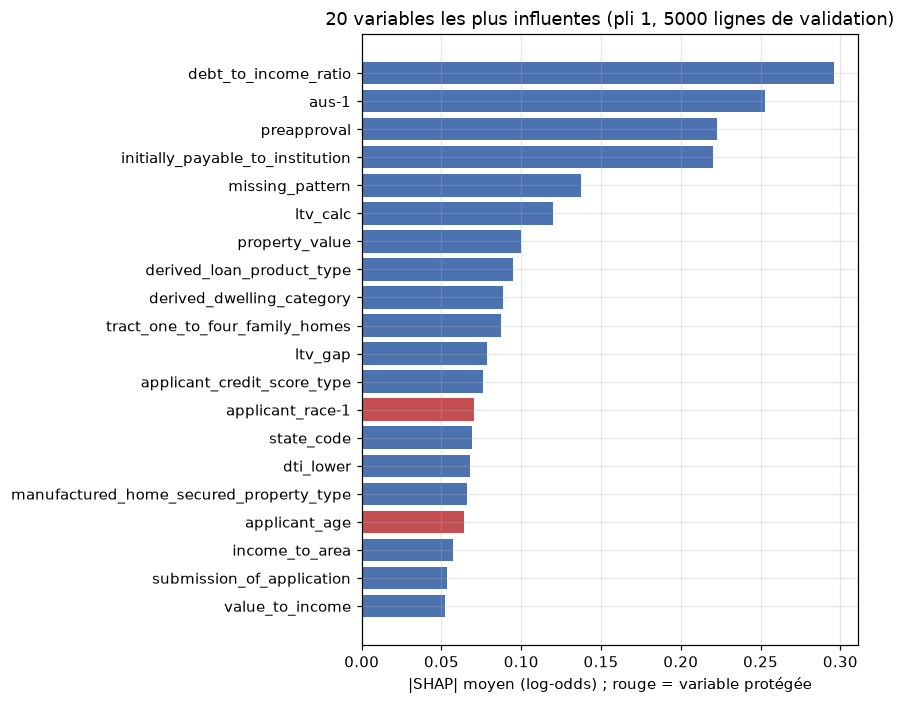

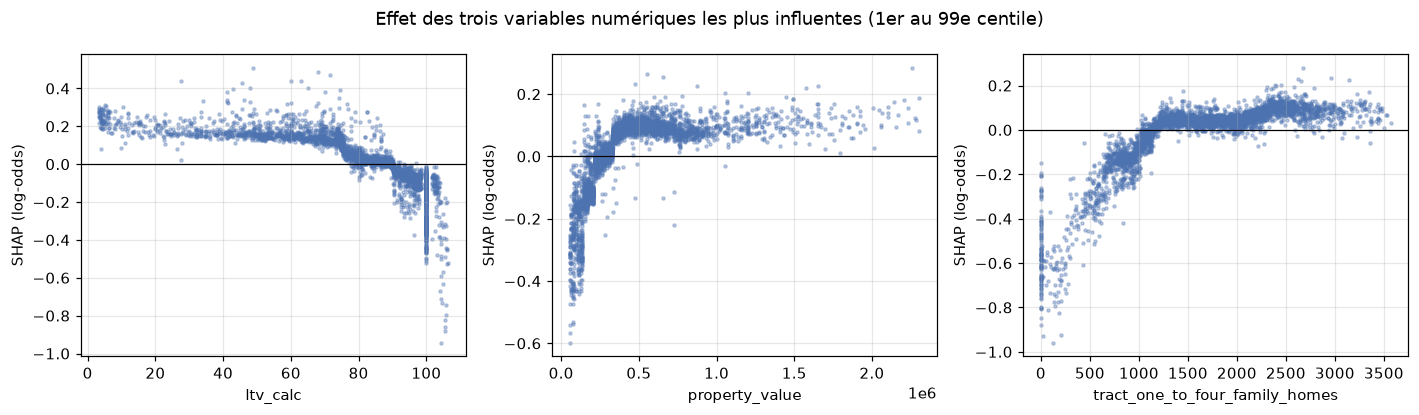

In [9]:
require(SHAP_PATH.is_file(), f'Valeurs de Shapley absentes ({SHAP_PATH.name}) : activer protected_ablation')
shap_frame = pd.read_parquet(SHAP_PATH)
shap_values = shap_frame.drop(columns=['id', 'expected_value'])
require(shap_values.columns.equals(full_train.columns) and len(shap_values) == SHAP_ROWS,
        'Valeurs de Shapley incompatibles avec les variables')
shap_rows = pd.Index(train_ids).get_indexer(shap_frame['id'].astype(str))
require((shap_rows >= 0).all() and (fold_assignment[shap_rows] == SHAP_FOLD).all(), 'Lignes de Shapley hors du pli attendu')
shap_features = full_train.iloc[shap_rows].reset_index(drop=True)
importance = shap_values.abs().mean().sort_values(ascending=False)


def family(column):
    if column in PROTECTED_COLUMNS:
        return 'Variables protégées (origine, sexe, âge)'
    if 'ltv' in column or column in {'loan_to_value_ratio', 'property_value'}:
        return 'LTV et valeur du bien'
    if column in {'debt_to_income_ratio', 'dti_lower', 'dti_upper', 'income',
                  'income_to_area', 'loan_to_income', 'value_to_income'}:
        return 'Endettement et revenu'
    if column in {'state_code', 'derived_msa-md', 'county_code', 'ffiec_msa_md_median_family_income'} or column.startswith('tract_'):
        return 'Géographie et secteur'
    if column in {'aus-1', 'submission_of_application', 'initially_payable_to_institution', 'preapproval',
                  'applicant_credit_score_type', 'co-applicant_credit_score_type'}:
        return 'Instruction du dossier (AUS, score, dépôt)'
    if column.startswith('missing_'):
        return 'Profil de valeurs manquantes'
    return 'Produit, montant et durée'


families = importance.groupby(importance.index.map(family)).agg(['size', 'sum'])
families.columns = ['Colonnes', 'Somme des |SHAP| moyens']
families['Part'] = families['Somme des |SHAP| moyens'] / importance.sum()
display_named(families.sort_values('Part', ascending=False).round(3))
print(f'Les 5 premières variables : {importance.head(5).sum() / importance.sum():.0%} du total ; '
      f'les 10 premières : {importance.head(10).sum() / importance.sum():.0%}.')

top = importance.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(range(len(top)), top.to_numpy(),
        color=['#c44e52' if c in PROTECTED_COLUMNS else '#4c72b0' for c in top.index])
ax.set_yticks(range(len(top)), top.index)
ax.set_xlabel('|SHAP| moyen (log-odds) ; rouge = variable protégée')
ax.set_title(f'20 variables les plus influentes (pli {SHAP_FOLD}, {SHAP_ROWS} lignes de validation)')
plt.tight_layout()
plt.show()

numeric_top = [c for c in importance.index if c not in full_cats][:3]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, column in zip(axes, numeric_top):
    values = shap_features[column]
    low, high = values.quantile([0.01, 0.99])
    keep = values.between(low, high)
    ax.scatter(values[keep], shap_values.loc[keep, column], s=4, alpha=0.35, color='#4c72b0')
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xlabel(column)
    ax.set_ylabel('SHAP (log-odds)')
fig.suptitle('Effet des trois variables numériques les plus influentes (1er au 99e centile)')
plt.tight_layout()
plt.show()

- L'**instruction du dossier** pèse le plus (24 % pour 6 colonnes) : système automatique de souscription utilisé (`aus-1`), pré-approbation, dépôt du dossier. Viennent ensuite l'endettement et le revenu (17 %), le produit (16 %), le LTV et la valeur du bien (14 %), la géographie (13 %).
- Le DTI est la première variable (8.5 %). Aucune ne domine : les cinq premières font 32 % du total, les dix premières 47 %.
- Les **17 variables protégées** font 12 % du total. La première, l'origine de l'emprunteur (`applicant_race-1`), est 13e ; son âge est 17e.
- `missing_pattern` est 5e : la liste des champs non renseignés d'un dossier est très informative.
- Le LTV agit par seuils : effet positif et stable jusqu'à 75–80 %, négatif au-delà, et chute nette autour de 100 %. C'est ce que les variables de précision et de seuils du notebook 02 cherchaient à capter. Un bien de moins de 200 000 $ environ pénalise le dossier ; au-delà de 400 000 $ la valeur ne joue plus.

Ces valeurs décrivent le modèle d'un seul pli, pas l'ensemble final, et une contribution n'est pas une cause : une variable peut porter l'information d'une autre qui manque dans les données (l'historique de crédit, par exemple).

## 3. Calibration

L'AUC ne mesure que l'ordre des dossiers. On vérifie ici que les probabilités elles-mêmes sont justes : les prédictions hors pli sont découpées en 20 tranches de même taille, et on compare dans chacune la probabilité moyenne au taux d'acceptation observé.

,Modèle,Taux moyen pour tous
AUC,0.9201,0.5000
Brier,0.0520,0.1275
Log-loss,0.1935,0.4228


Erreur de calibration (ECE, 20 tranches) : 0.0020 ; écart maximal dans une tranche : 0.0086.


,Lignes,Probabilité_moyenne,Taux_observé,Écart
0,5250,0.0066,0.0032,-0.0034
1,5250,0.1502,0.1484,-0.0018
2,5250,0.5989,0.6048,0.0058
3,5250,0.8419,0.8413,-0.0006
4,5250,0.8991,0.8990,-0.0001
5,5250,0.9227,0.9141,-0.0086
6,5250,0.9369,0.9322,-0.0047
7,5250,0.9465,0.9469,0.0003
8,5250,0.9539,0.9554,0.0015
9,5250,0.9596,0.9602,0.0005


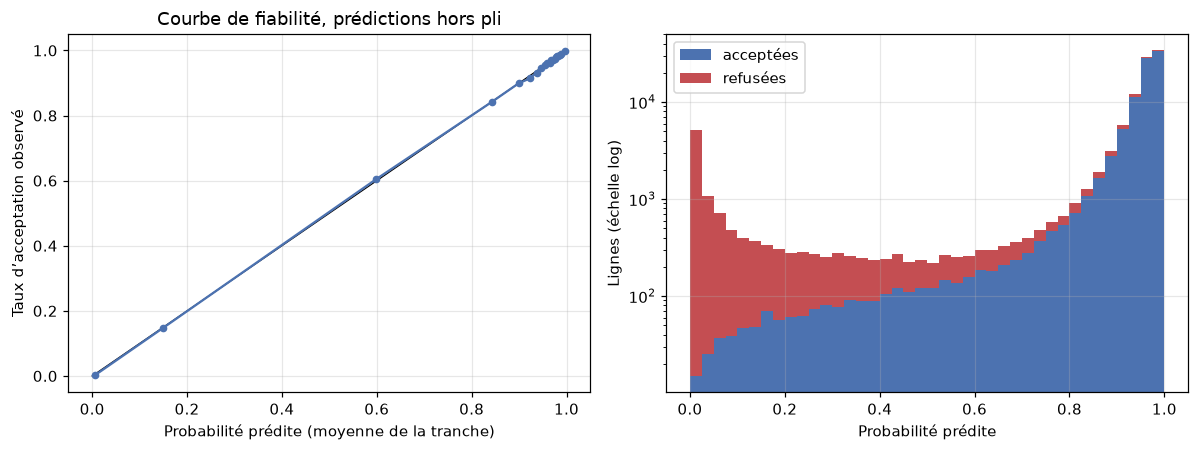

In [10]:
reference_oof = read_oof(OUTPUT_DIR, REFERENCE)
probability, actual = reference_oof['prob'], reference_oof['accepted']
bins = pd.qcut(probability, 20, duplicates='drop')
reliability = reference_oof.groupby(bins, observed=True).agg(
    Lignes=('prob', 'size'), Probabilité_moyenne=('prob', 'mean'), Taux_observé=('accepted', 'mean'))
reliability['Écart'] = reliability['Taux_observé'] - reliability['Probabilité_moyenne']
ece = float((reliability['Écart'].abs() * reliability['Lignes']).sum() / len(reference_oof))
base_rate = actual.mean()
summary = pd.DataFrame({
    'Modèle': {'AUC': roc_auc_score(actual, probability), 'Brier': brier_score_loss(actual, probability),
               'Log-loss': log_loss(actual, probability)},
    'Taux moyen pour tous': {'AUC': 0.5, 'Brier': base_rate * (1 - base_rate),
                             'Log-loss': log_loss(actual, np.full(len(actual), base_rate))},
})
display_named(summary.round(4))
print(f'Erreur de calibration (ECE, 20 tranches) : {ece:.4f} ; écart maximal dans une tranche : '
      f'{reliability["Écart"].abs().max():.4f}.')
display_named(reliability.reset_index(drop=True).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot([0, 1], [0, 1], color='black', lw=0.8)
axes[0].plot(reliability['Probabilité_moyenne'], reliability['Taux_observé'], marker='o', ms=4, color='#4c72b0')
axes[0].set_xlabel('Probabilité prédite (moyenne de la tranche)')
axes[0].set_ylabel('Taux d’acceptation observé')
axes[0].set_title('Courbe de fiabilité, prédictions hors pli')
axes[1].hist([probability[actual.eq(1)], probability[actual.eq(0)]], bins=40, stacked=True,
             color=['#4c72b0', '#c44e52'], label=['acceptées', 'refusées'])
axes[1].set_yscale('log')
axes[1].set_xlabel('Probabilité prédite')
axes[1].set_ylabel('Lignes (échelle log)')
axes[1].legend()
plt.tight_layout()
plt.show()

Le modèle est bien calibré sans aucune correction : l'erreur de calibration est de 0.0020 et l'écart le plus grand dans une tranche de 0.0086. Le score de Brier est de 0.052, contre 0.128 en prédisant le taux moyen pour tout le monde. L'histogramme montre aussi où sont les erreurs : la plupart des refus reçoivent une probabilité très basse, mais il en reste à tous les niveaux, y compris au-dessus de 0.9.

## 4. Par groupe

Pour chaque groupe d'au moins 500 lignes : taux d'acceptation observé, probabilité moyenne prédite (hors pli), écart entre les deux, et AUC calculée dans le groupe.

In [11]:
without_oof = read_oof(OUTPUT_DIR, WITHOUT_PROTECTED)
require(without_oof['id'].equals(reference_oof['id']), 'ID des deux variantes désalignés')
groups_frame = X_base.assign(id=train_ids.astype('int64').to_numpy()).merge(
    reference_oof[['id', 'accepted', 'prob']], on='id', validate='one_to_one').merge(
    without_oof[['id', 'prob']].rename(columns={'prob': 'prob_sans'}), on='id', validate='one_to_one')
GROUP_COLUMNS = {'derived_race': 'Origine', 'derived_ethnicity': 'Ethnicité',
                 'derived_sex': 'Sexe', 'applicant_age': 'Âge de l’emprunteur'}
MIN_GROUP_ROWS = 500


def group_table(column):
    rows = {}
    for value, part in groups_frame.groupby(column):
        if len(part) < MIN_GROUP_ROWS:
            continue
        rows[value] = {
            'Lignes': len(part), 'Taux observé': part['accepted'].mean(),
            'Probabilité moyenne': part['prob'].mean(),
            'Écart': part['accepted'].mean() - part['prob'].mean(),
            'AUC': roc_auc_score(part['accepted'], part['prob']),
            'Probabilité moyenne, sans': part['prob_sans'].mean(),
            'AUC, sans': roc_auc_score(part['accepted'], part['prob_sans']),
        }
    return pd.DataFrame(rows).T.sort_values('Lignes', ascending=False).astype({'Lignes': int})


GROUP_TABLES = {column: group_table(column) for column in GROUP_COLUMNS}
for column, label in GROUP_COLUMNS.items():
    print(f'\n{label} ({column}), groupes d’au moins {MIN_GROUP_ROWS} lignes')
    display_named(GROUP_TABLES[column][['Lignes', 'Taux observé', 'Probabilité moyenne', 'Écart', 'AUC']].round(4))


Origine (derived_race), groupes d’au moins 500 lignes


,Lignes,Taux observé,Probabilité moyenne,Écart,AUC
White,66107,0.8681,0.8682,-0.0001,0.9201
Race Not Available,17872,0.8276,0.8284,-0.0008,0.9225
Black or African American,8991,0.7387,0.7395,-0.0008,0.9095
Asian,8009,0.8891,0.8915,-0.0023,0.8830
Joint,2716,0.8722,0.8717,0.0005,0.9109
American Indian or Alaska Native,810,0.7272,0.7151,0.0121,0.9371



Ethnicité (derived_ethnicity), groupes d’au moins 500 lignes


,Lignes,Taux observé,Probabilité moyenne,Écart,AUC
Not Hispanic or Latino,70469,0.8653,0.8656,-0.0003,0.9197
Ethnicity Not Available,16232,0.8328,0.8328,0.0000,0.9236
Hispanic or Latino,15102,0.7934,0.7941,-0.0007,0.9104
Joint,3170,0.8685,0.8722,-0.0038,0.9166



Sexe (derived_sex), groupes d’au moins 500 lignes


,Lignes,Taux observé,Probabilité moyenne,Écart,AUC
Joint,38731,0.8833,0.8833,0.0000,0.9215
Male,34507,0.8447,0.8459,-0.0012,0.9041
Female,23462,0.8047,0.8043,0.0004,0.9329
Sex Not Available,8300,0.8437,0.8457,-0.0019,0.9137



Âge de l’emprunteur (applicant_age), groupes d’au moins 500 lignes


,Lignes,Taux observé,Probabilité moyenne,Écart,AUC
25-34,30933,0.8655,0.8656,-0.0002,0.9286
35-44,27055,0.8522,0.8530,-0.0009,0.9141
45-54,17437,0.8339,0.8359,-0.0021,0.9124
55-64,11993,0.8413,0.8392,0.0021,0.9211
<25,6763,0.8125,0.8120,0.0005,0.9358
65-74,5903,0.8536,0.8552,-0.0016,0.9136
MISSING,3088,0.8747,0.8750,-0.0003,0.8804
>74,1828,0.8496,0.8494,0.0002,0.9027


- **Les taux d'acceptation diffèrent beaucoup d'un groupe à l'autre** : 86.8 % pour les emprunteurs blancs, 73.9 % pour les emprunteurs noirs ; 86.5 % pour les non-hispaniques, 79.3 % pour les hispaniques ; 84.5 % pour les hommes seuls, 80.5 % pour les femmes seules. Ces écarts sont dans les données.
- **Le modèle les reproduit sans en ajouter** : dans chaque groupe la probabilité moyenne est à moins de 0.4 point du taux observé. Seule exception, les emprunteurs amérindiens (810 lignes), sous-estimés de 1.2 point.
- **La qualité du classement varie davantage** : l'AUC va de 0.883 (emprunteurs asiatiques) à 0.937, et de 0.904 pour les hommes seuls à 0.933 pour les femmes seules. Une partie de ces différences vient du taux d'acceptation de chaque groupe, qui change la difficulté du problème.

## 5. Sans les variables protégées

On compare les deux modèles pli par pli, puis les probabilités moyennes qu'ils donnent à chaque groupe.

In [12]:
ablation_runs = load_runs(OUTPUT_DIR)
require(len(ablation_runs) == 10, f'{len(ablation_runs)} entraînements trouvés, 10 attendus')
ablation_table, ablation_delta = paired_table(ablation_runs, 'group', REFERENCE, min_gain=0.0005)
per_fold = ablation_runs.pivot(index='fold', columns='group', values='valid_auc')[list(VARIANTS)]
per_fold['Écart'] = per_fold[WITHOUT_PROTECTED] - per_fold[REFERENCE]
display_named(per_fold.rename(columns=VARIANT_LABELS).round(5))
display_named(ablation_table.rename(index=VARIANT_LABELS).round(5))
print('Corrélation de Spearman entre les deux séries de prédictions hors pli : '
      f'{groups_frame["prob"].corr(groups_frame["prob_sans"], method="spearman"):.4f} ; '
      f'écart absolu moyen : {(groups_frame["prob"] - groups_frame["prob_sans"]).abs().mean():.4f}.')

spread = pd.DataFrame({
    label: {
        'Taux observé': np.ptp(GROUP_TABLES[column]['Taux observé']),
        'Probabilité moyenne, référence': np.ptp(GROUP_TABLES[column]['Probabilité moyenne']),
        'Probabilité moyenne, sans': np.ptp(GROUP_TABLES[column]['Probabilité moyenne, sans']),
    } for column, label in GROUP_COLUMNS.items()}).T
print('\nÉcart entre le groupe le plus accepté et le moins accepté')
display_named(spread.round(4))
for column, label in GROUP_COLUMNS.items():
    print(f'\n{label} ({column})')
    display_named(GROUP_TABLES[column][['Lignes', 'Taux observé', 'Probabilité moyenne',
                                        'Probabilité moyenne, sans', 'AUC', 'AUC, sans']].round(4))

group,Référence (68 colonnes),Sans variables protégées (51 colonnes),Écart
fold,,,
1,0.91427,0.91254,-0.00173
2,0.92742,0.92635,-0.00107
3,0.92067,0.91862,-0.00205
4,0.91655,0.91437,-0.00218
5,0.92157,0.91852,-0.00305


,folds,mean_auc,delta_vs_base,folds_better,keep
group,,,,,
Référence (68 colonnes),5,0.92009,0.00000,0,False
Sans variables protégées (51 colonnes),5,0.91808,-0.00201,0,False


Corrélation de Spearman entre les deux séries de prédictions hors pli : 0.9565 ; écart absolu moyen : 0.0140.

Écart entre le groupe le plus accepté et le moins accepté


,Taux observé,"Probabilité moyenne, référence","Probabilité moyenne, sans"
Origine,0.1620,0.1764,0.1722
Ethnicité,0.0750,0.0781,0.0771
Sexe,0.0786,0.0790,0.0794
Âge de l’emprunteur,0.0622,0.0630,0.0655



Origine (derived_race)


,Lignes,Taux observé,Probabilité moyenne,"Probabilité moyenne, sans",AUC,"AUC, sans"
White,66107,0.8681,0.8682,0.8630,0.9201,0.9188
Race Not Available,17872,0.8276,0.8284,0.8355,0.9225,0.9212
Black or African American,8991,0.7387,0.7395,0.7624,0.9095,0.9094
Asian,8009,0.8891,0.8915,0.8936,0.8830,0.8813
Joint,2716,0.8722,0.8717,0.8750,0.9109,0.9097
American Indian or Alaska Native,810,0.7272,0.7151,0.7215,0.9371,0.9385


... (2 outputs left out)


Sexe (derived_sex)


,Lignes,Taux observé,Probabilité moyenne,"Probabilité moyenne, sans",AUC,"AUC, sans"
Joint,38731,0.8833,0.8833,0.8826,0.9215,0.9185
Male,34507,0.8447,0.8459,0.8470,0.9041,0.9025
Female,23462,0.8047,0.8043,0.8032,0.9329,0.9316
Sex Not Available,8300,0.8437,0.8457,0.8510,0.9137,0.9115



Âge de l’emprunteur (applicant_age)


,Lignes,Taux observé,Probabilité moyenne,"Probabilité moyenne, sans",AUC,"AUC, sans"
25-34,30933,0.8655,0.8656,0.8617,0.9286,0.9261
35-44,27055,0.8522,0.8530,0.8561,0.9141,0.9126
45-54,17437,0.8339,0.8359,0.8423,0.9124,0.9120
55-64,11993,0.8413,0.8392,0.8404,0.9211,0.9196
<25,6763,0.8125,0.8120,0.8101,0.9358,0.9360
65-74,5903,0.8536,0.8552,0.8493,0.9136,0.9118
MISSING,3088,0.8747,0.8750,0.8756,0.8804,0.8787
>74,1828,0.8496,0.8494,0.8429,0.9027,0.9020


- **Le score baisse de 0.0020**, sur les cinq plis (de −0.0011 à −0.0031) : quatre fois notre critère de 0.0005. Les variables protégées apportent donc une information que les 51 autres colonnes ne contiennent pas entièrement.
- **Les écarts entre groupes restent presque les mêmes.** Entre emprunteurs blancs et noirs, l'écart de probabilité moyenne passe de 12.9 à 10.1 points ; entre non-hispaniques et hispaniques, de 7.2 à 6.6 points ; entre hommes et femmes seuls, il ne diminue pas (4.2 puis 4.4 points). Le modèle retrouve l'essentiel des écarts à partir du reste du dossier : DTI, LTV, type de prêt, secteur géographique.
- **Le modèle sans ces variables n'est plus calibré par groupe** : il surestime de 2.4 points l'acceptation des emprunteurs noirs (76.2 % prédits, 73.9 % observés) et sous-estime de 0.5 point celle des emprunteurs blancs.
- Les deux modèles classent les dossiers de façon proche (corrélation de Spearman 0.957), avec un écart moyen de 0.014 sur la probabilité.

Limites : `missing_pattern` indique encore si l'âge est renseigné, et les variables de secteur (`tract_minority_population_percent` en particulier) sont liées à l'origine. Le modèle « sans variables protégées » n'est donc pas aveugle à ces caractéristiques.

## 6. Bilan

- Le modèle s'appuie d'abord sur l'instruction du dossier, puis sur le DTI et le LTV, avec des effets de seuil cohérents avec les variables construites dans le notebook 02.
- Ses probabilités sont calibrées, globalement et dans chaque groupe.
- Les variables protégées représentent 12 % des contributions et 0.0020 d'AUC. Pour la compétition, nous les gardons : seul le score compte.
- Dans un usage réel, les retirer ne suffirait pas : le score baisse, les écarts entre groupes restent, et la calibration par groupe se dégrade. Ces écarts viennent des décisions passées que le modèle apprend à reproduire, pas d'une variable en particulier.
- La référence a tourné ici dans une troisième session (GPU T4) : 0.92009, contre 0.92015 dans le notebook 04, soit moins que la variabilité entre deux sessions.